# TP3 – Workflow Machine Learning : World Data Centers (scikit-learn, puis Spark)

## Ma contribution

**Le notebook est-il correct ?** Oui : la partie 1 (pandas/scikit-learn) et la partie 2 (Spark) ont été exécutées de bout en bout, sans erreur (sorties incluses). Seule la cellule d'imports/session Spark ajoutée au moment de séparer ce TP du suivant n'a pas été ré-exécutée.

**Problèmes rencontrés**
- Classes très déséquilibrées (67 % de sites `unclassified`, exclus de l'entraînement) et surface manquante pour ~19 % des sites : pondération des classes (`class_weight='balanced'`), F1 macro, imputation dans le pipeline.
- Risque de fuite de données : le nom des sites contient « AWS », « Equinix »… ; il n'est pas utilisé comme variable.
- La classe `telecom_carrier` reste la plus difficile à prédire (F1 0,45).
- Sous Windows, Spark exige `winutils.exe` et `hadoop.dll`.

**Modifications / ajouts**
- Workflow complet sur un jeu Kaggle : EDA, prétraitement, `Pipeline` + `ColumnTransformer`, régression logistique vs forêt aléatoire (CV 5 plis), évaluation, sauvegarde `joblib` et script de prédiction `predict_datacenter.py`.
- **PySpark** : le traitement initial n'utilisait pas Spark ; il est complété par la partie 2 (lecture, agrégation Spark SQL par pays jointe aux totaux officiels `reported_totals.csv`, pipeline MLlib avec forêt aléatoire).

**Autres informations** : meilleur modèle = forêt aléatoire (F1 macro CV 0,755 ; précision test 0,81). Données Kaggle non versionnées (`world_data/`).

---

Workflow : **Data → EDA → Prétraitement → Transformation → ML → Évaluation → Déploiement**

Jeu de données : [World Data Centers](https://www.kaggle.com/datasets/rockyt0/world-data-centers) (OpenStreetMap, 4 802 sites, 1 CSV).

| Partie | Outils |
|---|---|
| 1) Exemple « non Big Data » | pandas + scikit-learn |
| 2) Même workflow refait en Spark | PySpark MLlib |

Les CSV sont attendus dans `world_data/` (non versionné, cf. `.gitignore`).

In [1]:
import os, glob, warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
os.makedirs("models", exist_ok=True)

# Partie 1 – World Data Centers (pandas + scikit-learn)

**Problème** : à partir des caractéristiques d'un data center recensé dans OpenStreetMap (surface au sol, position, continent,
présence d'un opérateur, d'un site web…), prédire son **type** : `colocation`, `hyperscale` ou `telecom_carrier`.
(Les 3 226 sites `unclassified` n'ont pas de label : ils sont exclus de l'entraînement.)

## Data

In [2]:
dc = pd.read_csv("world_data/data_centers.csv", low_memory=False)
print(dc.shape); dc[["name","operator","facility_kind","country","continent","latitude","longitude","footprint_area_m2"]].head()

(4802, 32)


,name,operator,facility_kind,country,continent,latitude,longitude,footprint_area_m2
0,ISPPro.al,NaN,unclassified,Albania,Europe,42.121369,19.561237,110.0
1,NaN,NaN,unclassified,Angola,Africa,-14.813566,13.441489,69.0
2,Centro de Datos Modular REFSA Telecomunicaciones,NaN,telecom_carrier,Argentina,South America,-26.205855,-58.207081,NaN
3,Centro de Datos UPSTI,NaN,unclassified,Argentina,South America,-26.182862,-58.164591,NaN
4,Claro,NaN,unclassified,Argentina,South America,-30.866751,-64.519637,26.0


## EDA

facility_kind
unclassified            3226
colocation               723
hyperscale               604
telecom_carrier          160
research_or_academic      42
financial                 38
government_or_public       9
Name: count, dtype: int64 

% de valeurs manquantes (top 10) :
brand              99.4
wikipedia          98.9
name_en            98.3
wikidata           97.5
owner              97.1
height_m           96.5
start_date         96.0
operator_short     92.5
building_levels    91.5
state              81.5
dtype: float64


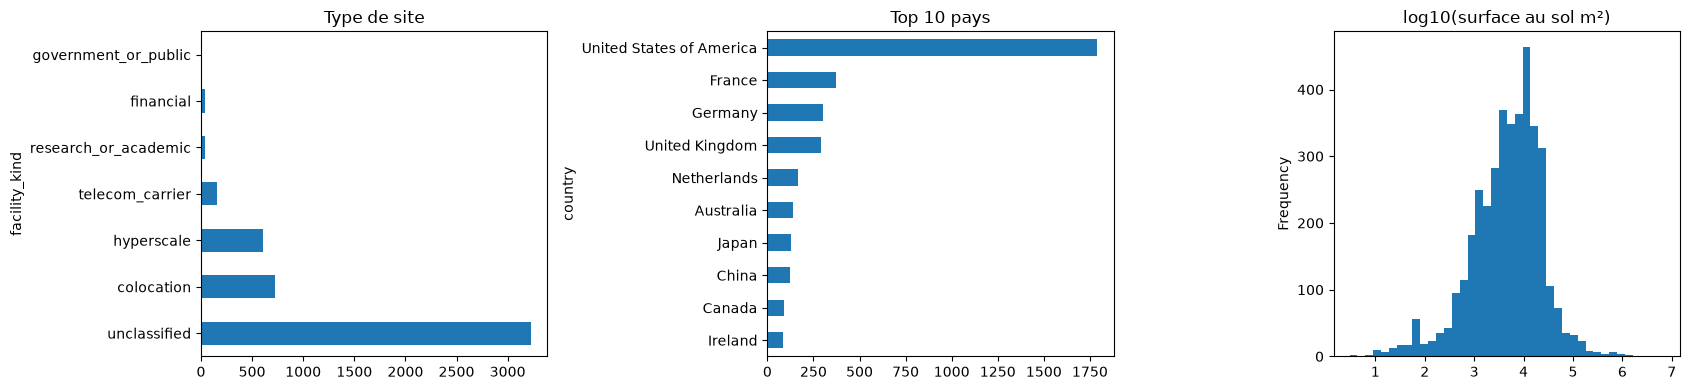

facility_kind
colocation               7406.0
financial                7090.0
government_or_public     1324.0
hyperscale              15675.0
research_or_academic     1452.0
telecom_carrier          2322.0
unclassified             3993.0
Name: footprint_area_m2, dtype: float64


In [3]:
print(dc.facility_kind.value_counts(), "\n")
print("% de valeurs manquantes (top 10) :"); print((dc.isna().mean()*100).round(1).sort_values(ascending=False).head(10))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
dc.facility_kind.value_counts().plot.barh(ax=ax[0], title="Type de site")
dc.country.value_counts().head(10).plot.barh(ax=ax[1], title="Top 10 pays").invert_yaxis()
np.log10(dc.footprint_area_m2.dropna()).plot.hist(bins=40, ax=ax[2], title="log10(surface au sol m²)")
plt.tight_layout(); plt.show()
print(dc.groupby("facility_kind").footprint_area_m2.median().round(0))

**Observations** : classes très déséquilibrées (67 % `unclassified`), surface manquante pour ~19 %, distribution de surface log-normale
(d'où le `log10`), les `hyperscale` sont nettement plus grands que les autres.

## Prétraitement

Filtrage des 3 classes cibles, suppression des identifiants/texte libre (risque de fuite : le nom contient souvent « AWS », « Equinix »…),
création d'indicateurs de présence, log de la surface, séparation train/test stratifiée **avant** toute imputation (pas de fuite).

In [4]:
from sklearn.model_selection import train_test_split
targets = ["colocation", "hyperscale", "telecom_carrier"]
d = dc[dc.facility_kind.isin(targets)].copy()
d["log_area"]     = np.log10(d.footprint_area_m2)
d["has_operator"] = d.operator.notna().astype(int)
d["has_name"]     = d.name.notna().astype(int)
d["has_website"]  = d.website.notna().astype(int)
d["has_city"]     = d.city.notna().astype(int)
d["is_way"]       = (d.osm_type == "way").astype(int)
num = ["log_area", "latitude", "longitude", "has_operator", "has_name", "has_website", "has_city", "is_way"]
cat = ["continent"]
X, y = d[num + cat], d.facility_kind
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(Xtr.shape, Xte.shape); ytr.value_counts(normalize=True).round(3)

(1115, 9) (372, 9)


facility_kind
colocation         0.486
hyperscale         0.406
telecom_carrier    0.108
Name: proportion, dtype: float64

## Transformation

Imputation (médiane) + standardisation des numériques, one-hot du continent, le tout dans un `Pipeline` scikit-learn.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

## ML

Deux modèles comparés par validation croisée (F1 macro, adapté au déséquilibre) : régression logistique et forêt aléatoire, avec `class_weight='balanced'`.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
models = {"LogReg": LogisticRegression(max_iter=2000, class_weight="balanced"),
          "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
pipes = {k: Pipeline([("prep", prep), ("m", m)]) for k, m in models.items()}
for k, p in pipes.items():
    s = cross_val_score(p, Xtr, ytr, cv=cv, scoring="f1_macro")
    print(f"{k:13s} F1-macro CV = {s.mean():.3f} ± {s.std():.3f}")

LogReg        F1-macro CV = 0.640 ± 0.020


RandomForest  F1-macro CV = 0.755 ± 0.038


## Éval

                 precision    recall  f1-score   support

     colocation       0.85      0.82      0.84       181
     hyperscale       0.87      0.88      0.88       151
telecom_carrier       0.43      0.47      0.45        40

       accuracy                           0.81       372
      macro avg       0.72      0.73      0.72       372
   weighted avg       0.81      0.81      0.81       372



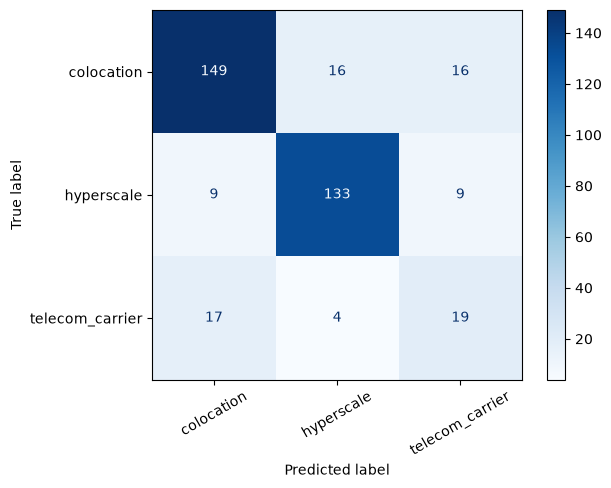

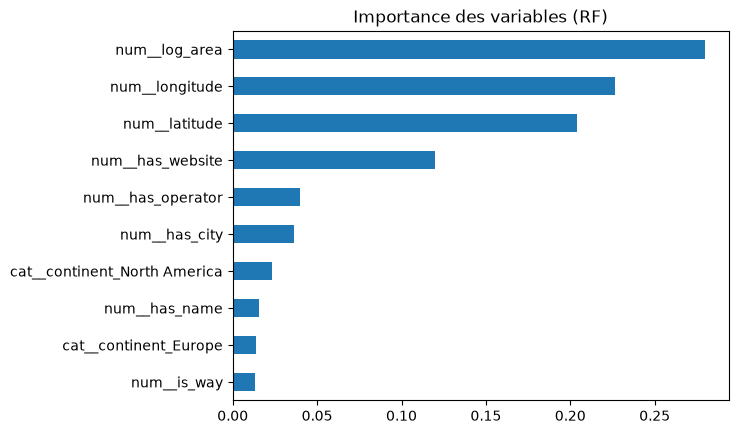

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
best_sk = pipes["RandomForest"].fit(Xtr, ytr)
pred = best_sk.predict(Xte)
print(classification_report(yte, pred))
ConfusionMatrixDisplay.from_predictions(yte, pred, xticks_rotation=30, cmap="Blues"); plt.show()
names = best_sk.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_sk.named_steps["m"].feature_importances_, index=names).sort_values()
imp.tail(10).plot.barh(title="Importance des variables (RF)"); plt.show()

## Déploiement

Sauvegarde du pipeline complet (prétraitement + modèle) avec `joblib` et fonction de prédiction réutilisable (cf. `predict_datacenter.py`).

In [8]:
import joblib
joblib.dump(best_sk, "models/datacenter_rf.joblib")
loaded = joblib.load("models/datacenter_rf.joblib")
new_site = pd.DataFrame([dict(log_area=np.log10(60000), latitude=45.5, longitude=-122.6, has_operator=1, has_name=1,
                              has_website=1, has_city=1, is_way=1, continent="North America")])
print("Prédiction :", loaded.predict(new_site)[0]); print(dict(zip(loaded.classes_, loaded.predict_proba(new_site)[0].round(3))))

Prédiction : colocation
{'colocation': np.float64(0.973), 'hyperscale': np.float64(0.02), 'telecom_carrier': np.float64(0.007)}


# Partie 2 – Refait avec Spark : World Data Centers avec MLlib

On rejoue le même workflow qu'en Partie 1 avec Spark (l'intérêt est la **portabilité** du code vers des volumes supérieurs) et on ajoute une
agrégation SQL par pays, jointe à `reported_totals.csv` (comptages officiels publiés), pour mesurer la couverture d'OpenStreetMap.

## Data

In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
spark = SparkSession.builder.master("local[*]").appName("TP3-DataCenters").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

## EDA
Lecture du CSV dans Spark et agrégation SQL par pays, jointe aux totaux officiels.

In [18]:
dcs = spark.read.csv("world_data/data_centers.csv", header=True, inferSchema=True, multiLine=True, escape='"')
dcs.createOrReplaceTempView("dc")
spark.read.csv("world_data/reported_totals.csv", header=True, inferSchema=True).createOrReplaceTempView("rep")
spark.sql('''SELECT d.country, COUNT(*) osm, MAX(r.reported_facilities) reported,
             ROUND(100*COUNT(*)/MAX(r.reported_facilities),1) pct_couverture_osm,
             SUM(CASE WHEN facility_kind='hyperscale' THEN 1 ELSE 0 END) hyperscale
             FROM dc d JOIN rep r ON d.country_iso3 = r.country_iso3
             GROUP BY d.country ORDER BY osm DESC LIMIT 10''').show(truncate=False)

+------------------------+----+--------+------------------+----------+
|country                 |osm |reported|pct_couverture_osm|hyperscale|
+------------------------+----+--------+------------------+----------+
|United States of America|3578|4088    |87.5              |886       |
|France                  |742 |346     |214.5             |2         |
|Germany                 |600 |507     |118.3             |0         |
|United Kingdom          |586 |506     |115.8             |18        |
|Netherlands             |334 |187     |178.6             |30        |
|Australia               |278 |270     |103.0             |30        |
|Japan                   |254 |255     |99.6              |2         |
|China                   |250 |369     |67.8              |4         |
|Canada                  |176 |286     |61.5              |6         |
|Ireland                 |172 |128     |134.4             |78        |
+------------------------+----+--------+------------------+----------+



## ML
Pipeline MLlib complet (transformation : `Imputer` → `StringIndexer` → `OneHotEncoder` → `VectorAssembler`, puis forêt aléatoire) et évaluation sur le jeu de test.

In [19]:
sd = (dcs.where(F.col("facility_kind").isin(targets))
      .withColumn("log_area", F.log10(F.col("footprint_area_m2").cast("double")))
      .withColumn("latitude", F.col("latitude").cast("double")).withColumn("longitude", F.col("longitude").cast("double"))
      .withColumn("has_operator", F.col("operator").isNotNull().cast("int"))
      .withColumn("has_name", F.col("name").isNotNull().cast("int"))
      .withColumn("has_website", F.col("website").isNotNull().cast("int"))
      .withColumn("has_city", F.col("city").isNotNull().cast("int"))
      .withColumn("is_way", (F.col("osm_type") == "way").cast("int")))
flags = ["has_operator", "has_name", "has_website", "has_city", "is_way"]
tr, te = sd.randomSplit([.75, .25], seed=42)
pipe = Pipeline(stages=[
    Imputer(inputCols=["log_area"], outputCols=["log_area_imp"], strategy="median"),
    StringIndexer(inputCol="facility_kind", outputCol="lab"), StringIndexer(inputCol="continent", outputCol="cont_idx", handleInvalid="keep"),
    OneHotEncoder(inputCols=["cont_idx"], outputCols=["cont_oh"]),
    VectorAssembler(inputCols=["log_area_imp", "latitude", "longitude"] + flags + ["cont_oh"], outputCol="features"),
    RandomForestClassifier(labelCol="lab", featuresCol="features", numTrees=200, maxDepth=8, seed=42)])
pm = pipe.fit(tr); p = pm.transform(te)
for m in ["accuracy", "f1"]: print(m, round(MulticlassClassificationEvaluator(labelCol="lab", metricName=m).evaluate(p), 4))
print("classes :", pm.stages[1].labels)

accuracy 0.7969


f1 0.7816
classes : ['colocation', 'hyperscale', 'telecom_carrier']


## Conclusion

# Conclusion

| | Partie 1 (pandas/sklearn) | Partie 2 (Spark MLlib) |
|---|---|---|
| Pipeline | `Pipeline` + `ColumnTransformer` | `Pipeline` MLlib (Imputer → Indexer → Assembler → forêt aléatoire) |
| Déploiement | `joblib` + `predict_datacenter.py` | — |

Points d'attention : **fuite de données** (les noms de sites ne sont pas utilisés pour prédire le type) et **déséquilibre de classes**.